# Noise, long signals and the two solvers

This notebook shows how to work with realistic data: noisy signals, long
signals with many lines, and the choice between the filter diagonalization
solver (default) and the Padé solver. Section 4 explores how far one can go
in signal-to-noise ratio, compared with the theoretical limit, and section 5
looks at the Padé solver in depth.

In [1]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt

from pyharminv import harminv, synthetic_signal
from pyharminv.signals import random_modes

plt.rcParams["figure.figsize"] = (9, 4)
rng = np.random.default_rng(42)

## 1. Noisy data and the tolerance `tol`

We add white noise to eight damped cosines. `tol` tells the solver the
relative noise level of the data: noise standard deviation divided by the
rms of the signal.

relative noise level: 0.031


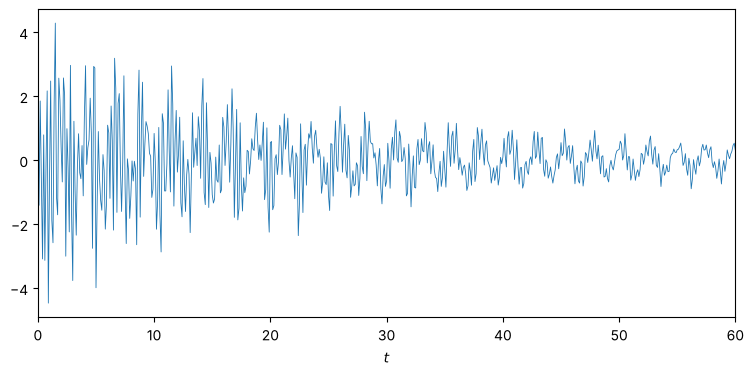

In [2]:
omega_true, d_true = random_modes(8, 1, 25, q_min=40, q_max=300,
                                  min_spacing=1.0, rng=rng)
dt = 0.1
t = dt * np.arange(1500)
noise = 0.02
x = synthetic_signal(t, omega_true, d_true, real=True, noise=noise, rng=rng)
rel_noise = noise / np.sqrt(np.mean(x ** 2))
print(f"relative noise level: {rel_noise:.3f}")

plt.plot(t, x, lw=0.6)
plt.xlabel("$t$"); plt.xlim(0, 60);

We deliberately choose a tolerance well below the noise level, so that
the solver also fits part of the noise:

In [3]:
result = harminv(x, dt, tol=0.01 * rel_noise)
print(len(result), "modes found for", len(omega_true), "true lines")

205 modes found for 8 true lines


Most of these modes are spurious. They have small amplitudes or large
error estimates, so they are easy to separate:

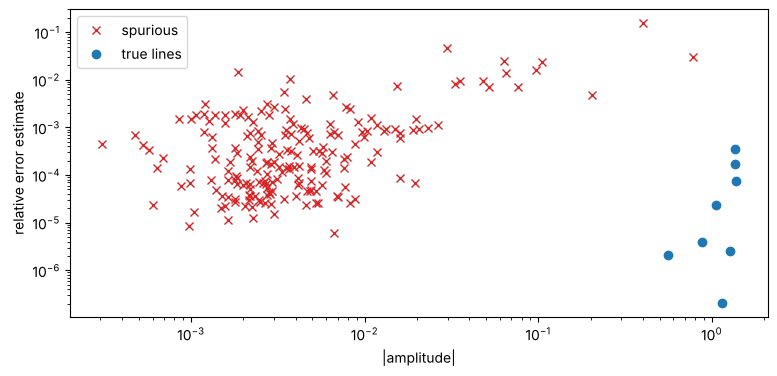

In [4]:
rel_err = result.error / np.abs(result.omega)
true_idx = [np.argmin(np.abs(result.omega - w)) for w in omega_true]
is_true = np.zeros(len(result), bool); is_true[true_idx] = True

plt.loglog(result.magnitude[~is_true], rel_err[~is_true], "x", color="C3", label="spurious")
plt.loglog(result.magnitude[is_true], rel_err[is_true], "o", color="C0", label="true lines")
plt.xlabel("|amplitude|"); plt.ylabel("relative error estimate"); plt.legend();

In [5]:
lines = result.select(min_magnitude=0.1, max_rel_error=1e-3)
print(len(lines), "modes after selection")
order = np.argsort(omega_true.real)
dev = [np.min(np.abs(lines.omega - w)) for w in omega_true[order]]
for w, e in zip(omega_true[order], dev):
    print(f"true omega {w.real:7.3f} {w.imag:+.4f}i   deviation {e:.1e}")

8 modes after selection
true omega   2.601 -0.0177i   deviation 1.5e-04
true omega   9.461 -0.0301i   deviation 5.6e-04
true omega  14.855 -0.0545i   deviation 1.7e-03
true omega  16.939 -0.0301i   deviation 1.4e-04
true omega  18.157 -0.0438i   deviation 1.2e-03
true omega  19.363 -0.0381i   deviation 9.3e-04
true omega  21.596 -0.0695i   deviation 2.3e-03
true omega  24.586 -0.1241i   deviation 1.5e-03


### Effect of `tol`

Too small a tolerance adds spurious modes, some of them strong enough that
the error filter of `select` is needed. Too large a tolerance loses weak or
broad lines. A tolerance near the relative noise level is the best default
here: it returns exactly the true lines.

In [6]:
for factor in [1e-3, 1e-2, 1e-1, 1, 10]:
    r = harminv(x, dt, tol=factor * rel_noise)
    s = r.select(min_magnitude=0.1)
    worst = max(np.min(np.abs(s.omega - w)) if len(s) else np.inf for w in omega_true)
    print(f"tol = {factor:6g} x noise: {len(r):4d} modes, {len(s):2d} strong, "
          f"worst line deviation {worst:.1e}")

tol =  0.001 x noise:  198 modes, 11 strong, worst line deviation 2.0e-03


tol =   0.01 x noise:  205 modes, 12 strong, worst line deviation 2.3e-03


tol =    0.1 x noise:  143 modes, 10 strong, worst line deviation 1.6e-02


tol =      1 x noise:    8 modes,  8 strong, worst line deviation 3.0e-03


tol =     10 x noise:    7 modes,  7 strong, worst line deviation 3.0e+00


## 2. Long signals with many lines

For long signals `harminv` splits the frequency range into windows and
solves each with filter diagonalization from the whole signal. Here are 100
lines in 50 000 samples.

In [7]:
omega_many, d_many = random_modes(100, 1, 60, q_min=100, q_max=2000,
                                  min_spacing=0.1, rng=rng)
dt = 0.05
t = dt * np.arange(50_000)
x = synthetic_signal(t, omega_many, d_many, real=True)

start = time.perf_counter()
many = harminv(x, dt)
print(f"{time.perf_counter() - start:.1f} s, {len(many.info['windows'])} windows")

strong = many.select(min_magnitude=1e-3)
dev = np.array([np.min(np.abs(strong.omega - w)) for w in omega_many])
print(len(strong), "strong modes; largest deviation from a true line:", dev.max())

35.9 s, 138 windows
100 strong modes; largest deviation from a true line: 7.05594902638995e-07


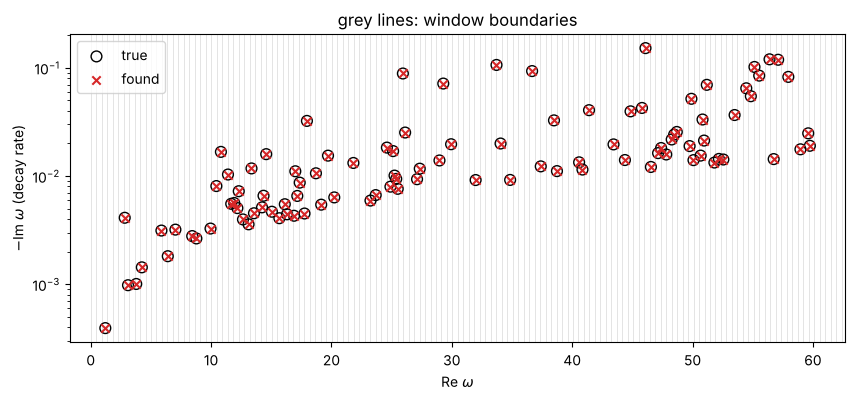

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(omega_many.real, -omega_many.imag, s=60, facecolors="none",
           edgecolors="k", label="true")
ax.scatter(strong.omega.real, -strong.omega.imag, marker="x", color="C3",
           label="found")
for lo, hi in many.info["windows"]:
    ax.axvline(lo, color="0.85", lw=0.5, zorder=0)
ax.set_yscale("log")
ax.set_xlabel(r"Re $\omega$"); ax.set_ylabel(r"$-$Im $\omega$ (decay rate)")
ax.set_title("grey lines: window boundaries"); ax.legend();

The frequency range can also be restricted, which saves time when
only part of the spectrum matters:

In [9]:
part = harminv(x, dt, omega_min=20, omega_max=22).select(min_magnitude=1e-3)
expected = np.sum((omega_many.real >= 20) & (omega_many.real <= 22))
print(len(part), "modes in [20, 22], expected", expected)

2 modes in [20, 22], expected 2


## 3. Filter diagonalization or Padé?

Both solvers are exact for noise-free data. The Padé solver
(`method="pade"`, as in Wiersig & Main) fits the whole band at once and is
limited to a few hundred samples. Filter diagonalization (default) scales to
long signals and is less sensitive to noise.

In [10]:
omega5, d5 = random_modes(5, 1, 25, q_min=50, q_max=500, min_spacing=1, rng=1)
dt = 0.1
t = dt * np.arange(300)

print("noise    FDM error   Pade error")
for noise in [0, 1e-4, 1e-3, 1e-2]:
    x5 = synthetic_signal(t, omega5, d5, real=True, noise=noise, rng=2)
    tol = max(noise / np.sqrt(np.mean(x5 ** 2)), 1e-10)
    errs = []
    for method in ["fdm", "pade"]:
        r = harminv(x5, dt, method=method, tol=tol).select(min_magnitude=0.1)
        errs.append(max(np.min(np.abs(r.omega - w)) if len(r) else np.inf for w in omega5))
    print(f"{noise:6g}   {errs[0]:9.1e}   {errs[1]:9.1e}")

noise    FDM error   Pade error


     0     2.8e-13     1.7e-14


0.0001     1.8e-05     2.1e-05


 0.001     1.8e-04     2.1e-04


  0.01     3.0e-03     2.1e-03


Both reach rounding accuracy without noise and errors proportional to
the noise otherwise. Use the Padé solver to reproduce the method of the
paper or for very short signals, and the default otherwise.

## 4. How far does it go? Signal-to-noise limits

We now push the noise up and compare with what is possible in principle.
Throughout, the test signal is a single damped cosine
$x(t) = A e^{-\gamma t}\cos(\Omega t - \varphi)$ plus white Gaussian noise of
standard deviation $\sigma$, and we define the signal-to-noise ratio by the
initial amplitude:

$$\mathrm{SNR} = 20 \log_{10}(A/\sigma)\ \mathrm{dB}.$$

With $\gamma = 0.05$, $\Delta t = 0.1$ and 400 samples the line decays over
about 200 samples, so the information is spread over many noisy samples:
lines remain detectable even when $\sigma > A$.

### 4.1 Accuracy and the Cramér–Rao bound

No unbiased estimator can beat the Cramér–Rao bound (CRB), the inverse
Fisher information of the model. For white Gaussian noise it follows from
the derivatives of the signal with respect to the parameters. The new method
`HarmInvResult.refine` polishes harmonic inversion results by nonlinear
least squares (the maximum likelihood estimate for this noise), which is
expected to reach the bound.

Three solvers are compared: filter diagonalization (default), the
least-squares Padé solver (`method="pade"`, which uses all samples) and the
classical robust Padé approximant of Wiersig and Main
(`pade_variant="robust"`, here from the first 200 samples). Section 5
explains the difference between the two Padé variants.

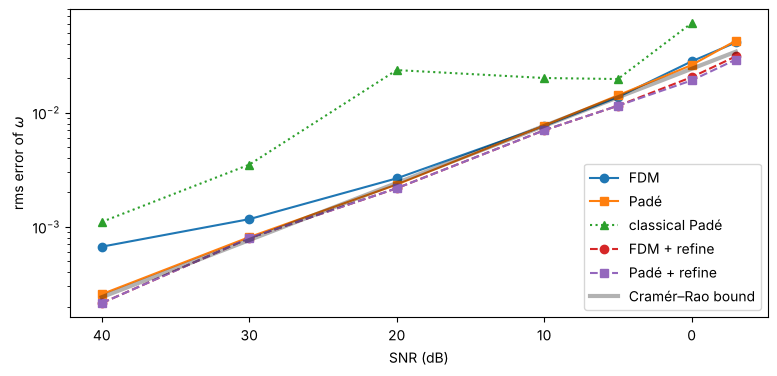

In [11]:
import warnings
warnings.filterwarnings("ignore")

dt, N = 0.1, 400
t = dt * np.arange(N)
Om, gam, A0, ph = 5.0, 0.05, 1.0, 0.3
omega0 = Om - 1j * gam

def damped_cosine(Om=Om, gam=gam, A=A0, ph=ph):
    return A * np.exp(-gam * t) * np.cos(Om * t - ph)

def crb_omega(sigma):
    """Cramér-Rao bound for |delta omega| (Re and Im combined)."""
    theta = np.array([Om, gam, A0, ph])
    D = []
    for i in range(4):
        h = 1e-6 * max(1, abs(theta[i]))
        tp, tm = theta.copy(), theta.copy()
        tp[i] += h; tm[i] -= h
        D.append((damped_cosine(*tp) - damped_cosine(*tm)) / (2 * h))
    D = np.array(D).T
    cov = sigma ** 2 * np.linalg.inv(D.T @ D)
    return np.sqrt(cov[0, 0] + cov[1, 1])

clean = damped_cosine()
snr_db = np.array([40, 30, 20, 10, 5, 0, -3])
methods = {"FDM": dict(method="fdm"), "Padé": dict(method="pade"),
           "classical Padé": dict(method="pade", pade_variant="robust", K=100)}
rms_err = {name: [] for name in ["FDM", "Padé", "classical Padé", "FDM + refine", "Padé + refine"]}
found = {name: [] for name in rms_err}
rng = np.random.default_rng(0)
n_rep = 25

for snr in snr_db:
    sigma = A0 * 10 ** (-snr / 20)
    errs = {name: [] for name in rms_err}
    for _ in range(n_rep):
        x = clean + sigma * rng.standard_normal(N)
        tol = sigma / np.sqrt(np.mean(x ** 2))
        for name, kw in methods.items():
            r = harminv(x, dt, tol=tol, **kw).select(min_magnitude=0.3)
            if len(r) == 0:
                continue
            k = np.argmax(r.magnitude)          # the strongest mode
            e = abs(r.omega[k] - omega0)
            if e < 0.1:
                errs[name].append(e)
                if name + " + refine" in errs:
                    r1 = r[k].refine(x, dt)
                    errs[name + " + refine"].append(abs(r1.omega[0] - omega0))
    for name in rms_err:
        e = np.array(errs[name])
        rms_err[name].append(np.sqrt(np.mean(e ** 2)) if len(e) else np.nan)
        found[name].append(len(e) / n_rep)

crb = [crb_omega(A0 * 10 ** (-s / 20)) for s in snr_db]
styles = {"FDM": "o-", "Padé": "s-", "classical Padé": "^:", "FDM + refine": "o--",
          "Padé + refine": "s--"}
for name, e in rms_err.items():
    plt.semilogy(snr_db, e, styles[name], label=name)
plt.semilogy(snr_db, crb, "k-", lw=3, alpha=0.3, label="Cramér–Rao bound")
plt.xlabel("SNR (dB)"); plt.ylabel(r"rms error of $\omega$"); plt.legend()
plt.gca().invert_xaxis();

* Filter diagonalization and least-squares Padé stay within a factor of
  about 1.5 of the bound down to 0 dB.
* The classical Padé approximant is several times worse and fails first.
  With noise its rank reduction either keeps spurious near-cancelling
  pole pairs or determines the approximant from too few samples
  (section 5). Its spurious modes can be strong, so it is left out of the
  detection test below, which simply looks at the strongest mode.
* `refine()` lands on the bound from either starting point.
* The accuracy only degrades in proportion to $\sigma$: there is no sudden
  breakdown until the line can no longer be told apart from the noise.

`refine()` also returns error bars estimated from the fit. They agree with
the actual scatter:

In [12]:
sigma = 0.3
x = clean + sigma * rng.standard_normal(N)
r = harminv(x, dt, tol=sigma / np.sqrt(np.mean(x ** 2))).select(min_magnitude=0.3)
fit = r.refine(x, dt)
print("estimated noise sigma:", fit.info["sigma"], "(true 0.3)")
print("omega =", fit.omega[0], "+/-", fit.error[0])
print("true deviation      :", abs(fit.omega[0] - omega0))
print("Cramér-Rao bound    :", crb_omega(sigma))

estimated noise sigma: 0.30864076196412604 (true 0.3)
omega = (5.000935552164658-0.05417514710584106j) +/- 0.007842553486969512
true deviation      : 0.004278681012673116
Cramér-Rao bound    : 0.007242362636530671


### 4.2 Detection limit

Where does the line get lost? The fraction of noise realisations in which
the strongest mode lies on the true line:

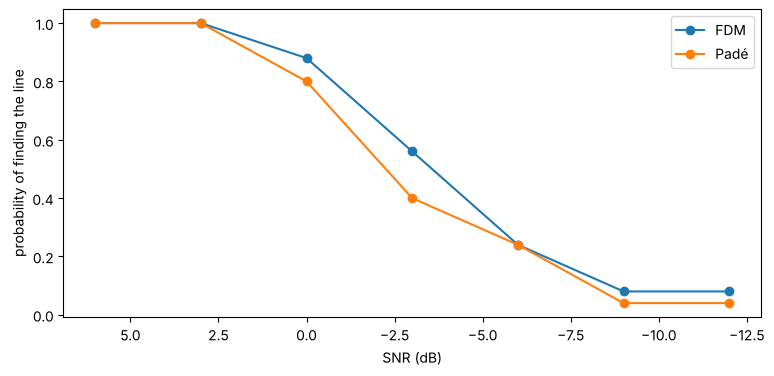

In [13]:
snr_fine = np.arange(6, -13, -3)
detect = {name: methods[name] for name in ["FDM", "Padé"]}
p_found = {name: [] for name in detect}
for snr in snr_fine:
    sigma = A0 * 10 ** (-snr / 20)
    hits = {name: 0 for name in detect}
    for _ in range(25):
        x = clean + sigma * rng.standard_normal(N)
        tol = sigma / np.sqrt(np.mean(x ** 2))
        for name, kw in detect.items():
            r = harminv(x, dt, tol=tol, **kw)
            if len(r):
                k = np.argmax(r.magnitude)
                hits[name] += abs(r.omega[k].real - Om) < 2 * gam
    for name in hits:
        p_found[name].append(hits[name] / 25)

for name, p in p_found.items():
    plt.plot(snr_fine, p, "o-", label=name)
plt.xlabel("SNR (dB)"); plt.ylabel("probability of finding the line")
plt.gca().invert_xaxis(); plt.legend();

The line is found reliably down to roughly 0 dB, i.e. noise as large
as the initial amplitude, and half the time around −5 dB. What counts is
the energy of the line relative to the noise: here about
$1/(2\gamma\,\Delta t) = 100$ samples contribute, which gains about 20 dB
over the single-sample SNR. A longer-lived line is detectable at even lower
SNR; a short-lived one needs more.

### 4.3 Resolving two close lines

Two lines of equal strength and width $\Gamma = 0.1$ are placed a fraction
of the Fourier resolution $2\pi/T$ apart. A map of the success rate shows
how resolution trades against noise. For this task a tolerance *below* the
noise level (here 0.1 σ) works better, because the rank decision must not
merge the two lines; spurious modes are then removed by `select` and the
pair is polished with `refine`.

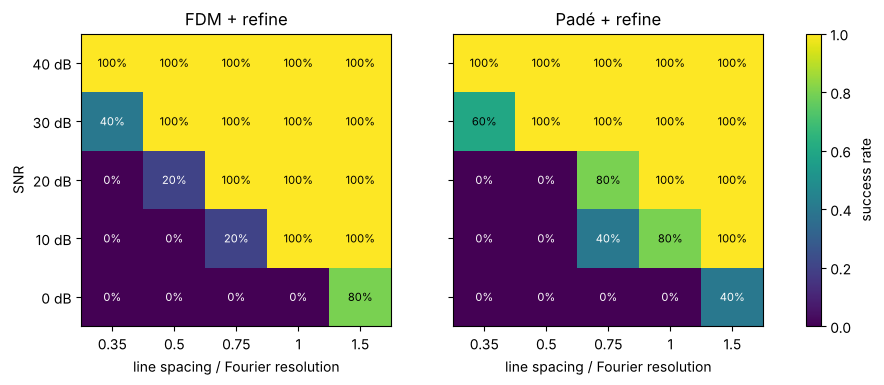

In [14]:
T = N * dt
fourier_res = 2 * np.pi / T
fractions = np.array([0.35, 0.5, 0.75, 1.0, 1.5])
snr_map = np.array([40, 30, 20, 10, 0])
n_rep = 5

def resolved(method, sigma, frac):
    w = np.array([5 - 0.05j, 5 + frac * fourier_res - 0.05j])
    x = synthetic_signal(t, w, [1.0, 1.0], real=True, noise=sigma, rng=rng)
    tol = 0.1 * sigma / np.sqrt(np.mean(x ** 2))
    r = harminv(x, dt, method=method, tol=tol, omega_min=3, omega_max=7)
    r = r.select(min_magnitude=0.3)
    if 2 <= len(r) <= 8:
        r = r.refine(x, dt).select(min_magnitude=0.3)
    return len(r) >= 2 and all(np.min(np.abs(r.omega - wi)) < 0.25 * frac * fourier_res
                               for wi in w)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, method in zip(axes, ["fdm", "pade"]):
    rate = np.array([[np.mean([resolved(method, 10 ** (-s / 20), f) for _ in range(n_rep)])
                      for f in fractions] for s in snr_map])
    im = ax.imshow(rate, cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(fractions)), [f"{f:g}" for f in fractions])
    ax.set_yticks(range(len(snr_map)), [f"{s} dB" for s in snr_map])
    ax.set_xlabel("line spacing / Fourier resolution")
    ax.set_title(f"{method.upper() if method == 'fdm' else 'Padé'} + refine")
    for i in range(rate.shape[0]):
        for j in range(rate.shape[1]):
            ax.text(j, i, f"{rate[i, j]:.0%}", ha="center", va="center",
                    color="w" if rate[i, j] < 0.6 else "k", fontsize=8)
axes[0].set_ylabel("SNR")
fig.colorbar(im, ax=axes, label="success rate");

At high SNR both solvers separate lines a third of the Fourier
resolution apart, and noise-free data allows far less (section 4 of the
first notebook). Every 10 dB of noise costs roughly a factor of 1.5 to 2 in
resolvable spacing; at 0 dB the lines must be more than a resolution cell
apart. This is the general rule for super-resolution: it is paid for with
signal-to-noise ratio.

### 4.4 Record length

Once the line has decayed, further samples are pure noise. Extending the
record beyond a few decay times $1/\gamma$ does not improve the estimate:

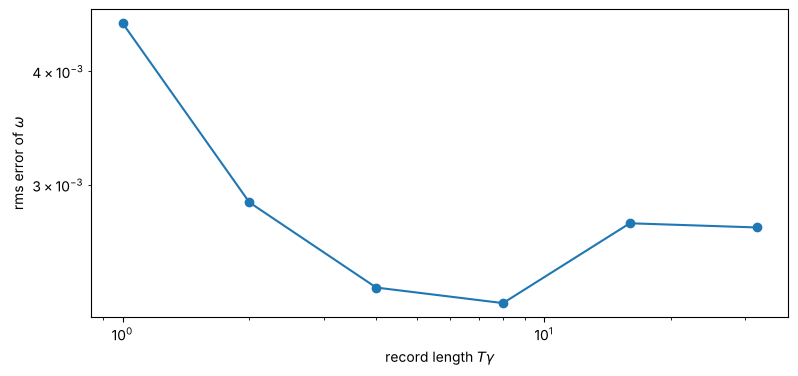

In [15]:
lengths = np.array([1, 2, 4, 8, 16, 32])          # in units of 1/gamma
sigma = 0.1
err_len = []
for L in lengths:
    n = int(L / gam / dt)
    tt = dt * np.arange(n)
    errs = []
    for _ in range(20):
        x = np.exp(-gam * tt) * np.cos(Om * tt) + sigma * rng.standard_normal(n)
        r = harminv(x, dt, tol=sigma / np.sqrt(np.mean(x ** 2))).select(min_magnitude=0.3)
        if len(r):
            errs.append(np.min(np.abs(r.omega - omega0)))
    err_len.append(np.sqrt(np.mean(np.square(errs))))

plt.loglog(lengths, err_len, "o-")
plt.xlabel(r"record length $T\gamma$"); plt.ylabel(r"rms error of $\omega$");

The error stops improving after about four to eight decay times; the
small rise beyond that is statistical scatter of 20 trials. Recording
longer only costs computing time; cutting the signal there is a simple way
to raise the effective SNR.

### Summary

| goal | recommendation |
|---|---|
| best accuracy of isolated lines | `tol` ≈ relative noise level, then `refine()` |
| resolve close lines | `tol` ≈ 0.1 × noise level, `select`, then `refine()` |
| weak lines | record a few decay times, not more; check `error` |
| error bars | from `refine()` (`error`, `info["omega_std"]`) |


## 5. The Padé solver in depth

The Padé solver follows Wiersig and Main directly. The samples $c_n$ are
read as Taylor coefficients of

$$g(x) = \sum_n c_n x^n = \sum_k \frac{d_k}{1 - z_k x}, \qquad z_k = e^{-i\omega_k \Delta t},$$

which is a rational function. Its type $(K-1, K)$ Padé approximant from
$2K$ samples has poles at $x_k = 1/z_k$ and residues $-d_k/z_k$.
Decaying modes have $|z_k| < 1$, so their poles lie *outside* the unit
circle; the angle of the pole gives $\mathrm{Re}\,\omega_k$, the distance
from the circle the damping.

### 5.1 Poles and zeros in the complex plane

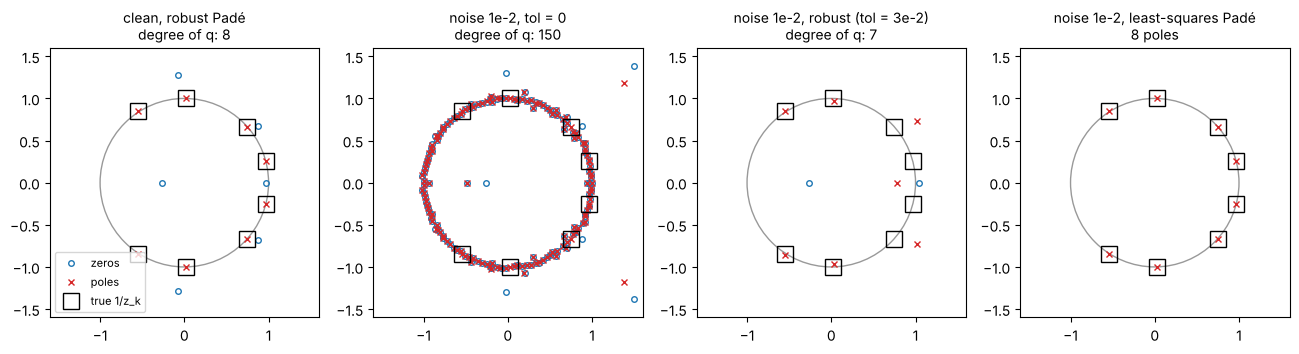

In [16]:
from pyharminv import padeapprox, harminv_window

omega4, d4 = random_modes(4, 1, 25, q_min=50, q_max=300, min_spacing=2, rng=3)
dt, N = 0.1, 300
t = dt * np.arange(N)
K = N // 2
true = np.exp(1j * omega4 * dt)                        # 1/z_k
true = np.concatenate([true, np.conj(true)])           # real signal: mirror modes

def frame(ax, title):
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="0.6"))
    ax.plot(true.real, true.imag, "s", ms=11, mfc="none", color="k", label="true 1/z_k")
    ax.set_aspect("equal"); ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6)
    ax.set_title(title, fontsize=10)

def pole_plot(ax, c, tol, title):
    p = padeapprox(c[:2 * K], K - 1, K, tol=tol)
    ax.plot(p.zeros.real, p.zeros.imag, "o", ms=4, mfc="none", color="C0", label="zeros")
    ax.plot(p.poles.real, p.poles.imag, "x", ms=5, color="C3", label="poles")
    frame(ax, f"{title}\ndegree of q: {p.nu}")

x_clean = synthetic_signal(t, omega4, d4, real=True)
x_noisy = synthetic_signal(t, omega4, d4, real=True, noise=1e-2, rng=1)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
pole_plot(axes[0], x_clean, 1e-12, "clean, robust Padé")
pole_plot(axes[1], x_noisy, 0, "noise 1e-2, tol = 0")
pole_plot(axes[2], x_noisy, 3e-2, "noise 1e-2, robust (tol = 3e-2)")
w, d, _ = harminv_window(x_noisy, dt, tol=0.03)
x_ls = np.exp(1j * w * dt)
axes[3].plot(x_ls.real, x_ls.imag, "x", ms=5, color="C3")
frame(axes[3], f"noise 1e-2, least-squares Padé\n{len(w)} poles")
axes[0].legend(loc="lower left", fontsize=8);

* Clean data: the rank reduction finds exactly the eight poles (four
  modes and their mirror images) and nothing else.
* Noisy data without robustness: the approximant has full degree $K = 150$.
  The extra poles come with zeros right next to them, so-called *Froissart
  doublets*, lined up near the unit circle. Each doublet nearly cancels, but
  they spoil the residues and add spurious modes.
* With a tolerance above the noise level the doublets disappear, but the
  robust algorithm also loses genuine poles and misplaces others: as it
  hops down the Padé table it repeats the rank decision on ever smaller
  matrices, and the final approximant is determined by very few samples
  (section 5.3).
* The least-squares variant makes the rank decision once, on all samples,
  and finds all eight poles.

### 5.2 Choosing the tolerance from the singular values

The robust algorithm decides the degree from the singular values of a
Toeplitz matrix of the samples. Plotting them shows the decision directly:
one singular value per pole stands out above a plateau set by the noise.

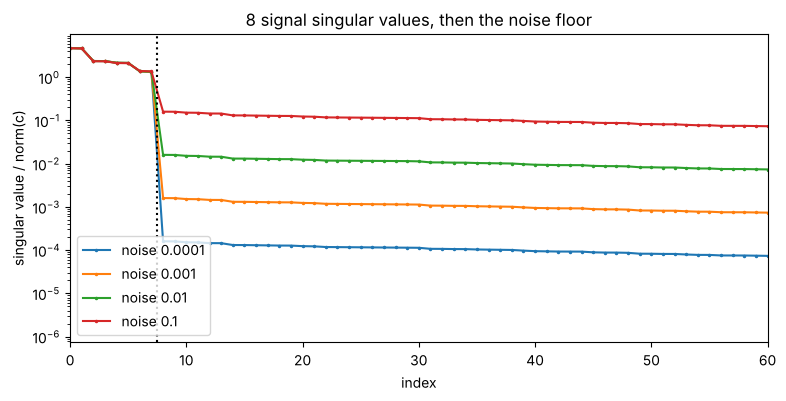

In [17]:
from scipy.linalg import toeplitz, svdvals

def toeplitz_singular_values(c, K):
    m, n = K - 1, K
    c = c[:2 * K]
    Z = toeplitz(c[:m + n + 1], np.r_[c[0], np.zeros(n)])
    return svdvals(Z[m + 1:m + n + 1]) / np.linalg.norm(c)

for noise in [1e-4, 1e-3, 1e-2, 1e-1]:
    x = synthetic_signal(t, omega4, d4, real=True, noise=noise, rng=1)
    plt.semilogy(toeplitz_singular_values(x, K), ".-", ms=3, label=f"noise {noise:g}")
plt.axvline(7.5, color="k", ls=":")
plt.xlabel("index"); plt.ylabel("singular value / norm(c)"); plt.xlim(0, 60)
plt.legend(); plt.title("8 signal singular values, then the noise floor");

The plateau sits at roughly $1.6\,\sigma$ relative to the norm of the
data here, and a rank threshold should lie between the plateau and the
smallest genuine singular value. The least-squares Padé solver makes exactly
this decision on the Hankel matrix of all samples, with the threshold
`tol` (the relative noise level) times the largest singular value. When the
noise reaches the weakest genuine singular values, no threshold can separate
them, which is the detection limit of section 4 seen from the Padé side.

### 5.3 Classical and least-squares Padé

The rank reduction has a price. Once the robust algorithm has found that
only $\nu$ poles are supported, the result is the type $(\nu-1, \nu)$
approximant, and a Padé approximant of that type is determined by the first
$2\nu$ coefficients alone. For eight poles that is 16 of 300 samples: the
noise in them is not averaged out at all.

The least-squares variant (the default for `method="pade"`) keeps the
rank decision but determines the $\nu$ poles from all samples: it
truncates the Hankel matrix of the whole signal to rank $\nu$ and finds the
$z_k$ as eigenvalues of the shift on its dominant subspace (matrix pencil),
then the amplitudes by linear least squares. It is exact for clean data,
like the classical approximant, and much more accurate for noisy data:

In [18]:
print("          classical Padé           least-squares")
print("noise     low tol    tol = noise      Padé           FDM")
for noise in [1e-6, 1e-4, 1e-3, 1e-2, 1e-1]:
    x = synthetic_signal(t, omega4, d4, real=True, noise=noise, rng=1)
    rel = noise / np.sqrt(np.mean(x ** 2))
    worst = []
    for kw in [dict(method="pade", pade_variant="robust", tol=rel),   # uses tol/100
               dict(method="pade", pade_variant="robust", tol=100 * rel),
               dict(method="pade", tol=rel), dict(method="fdm", tol=rel)]:
        r = harminv(x, dt, **kw).select(min_magnitude=0.3)
        worst.append(max(np.min(np.abs(r.omega - w)) if len(r) else np.inf
                         for w in omega4))
    print(f"{noise:6g}  " + "".join(f"{e:11.1e}    " for e in worst))

          classical Padé           least-squares
noise     low tol    tol = noise      Padé           FDM


 1e-06      6.9e-08        4.2e-04        5.2e-08        4.7e-08    


0.0001      6.9e-06        4.2e-02        5.2e-06        4.7e-06    


 0.001      6.9e-05        5.0e+00        5.2e-05        3.1e-04    


  0.01      6.9e-04        5.9e+00        5.1e-04        3.7e-04    


   0.1      6.8e-03        1.0e+01        4.7e-03        4.0e-03    


With a low tolerance the classical approximant keeps nearly full
degree, uses all $2K = 300$ samples and does reasonably well here, at the
price of many spurious modes. With a tolerance at the noise level the rank
reduction kicks in, the approximant is built from a few samples, and lines
are lost or misplaced (errors of order 1). The least-squares variant and
filter diagonalization need no such compromise; their errors are
proportional to the noise.

### 5.4 Which solver when?

| | Padé, least squares (`method="pade"`) | classical Padé (`pade_variant="robust"`) | filter diagonalization (default) |
|---|---|---|---|
| idea | rank-reduced fit of the poles to all samples | robust Padé approximant of $\sum c_n x^n$ | eigenproblem in a local Fourier basis |
| samples used | all | first $2K$, after rank reduction $2\nu$ | all |
| cost | SVD of an $N \times N/3$ matrix; up to a few thousand samples | $\propto K^3$ | windows of ≈ 150 basis functions; $10^5$ samples in seconds |
| frequency range | whole band | whole band | any sub-range, windows chosen automatically |
| noise | ≈ 1–1.5 × Cramér–Rao bound | far above the bound | ≈ 1–1.5 × Cramér–Rao bound |
| spurious modes | few, removed by `select` | Froissart doublets, removed by the rank reduction | weak, large `error`, removed by `select` |

All are exact for noise-free data, and `refine()` takes any of them to the
Cramér–Rao bound. The least-squares Padé solver is a good choice for short
and medium signals and an independent cross-check of filter
diagonalization: lines found by both are trustworthy. The classical variant
reproduces the method of Wiersig and Main. The third notebook shows Padé
approximation as a tool beyond harmonic inversion.